In [8]:
!pip install numpy pandas
import numpy as np
import pandas as pd

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: C:\Program Files\Python312\python.exe -m pip install --upgrade pip


ModuleNotFoundError: No module named 'numpy'

In [ ]:
df=pd.read_csv("uber.csv")

In [ ]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [ ]:
df.columns

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [ ]:
df.shape

(200000, 9)

In [ ]:
df['passenger_count'].isnull().sum()

np.int64(0)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: ylabel='fare_amount'>

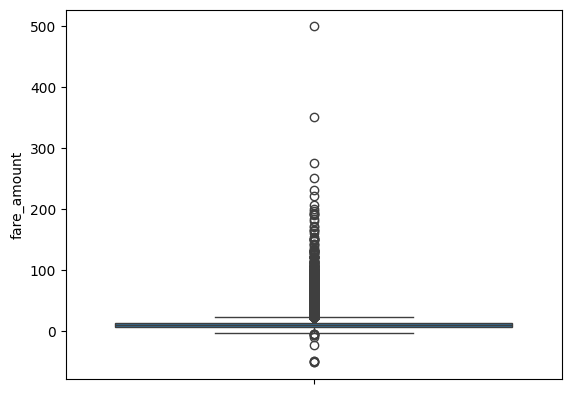

In [ ]:
sns.boxplot(df['fare_amount'])

In [ ]:
df['fare_amount'].min()

np.float64(-52.0)

In [ ]:
df=df[(df['fare_amount']>0) & (df['fare_amount']<=25)]

<Axes: xlabel='fare_amount', ylabel='Count'>

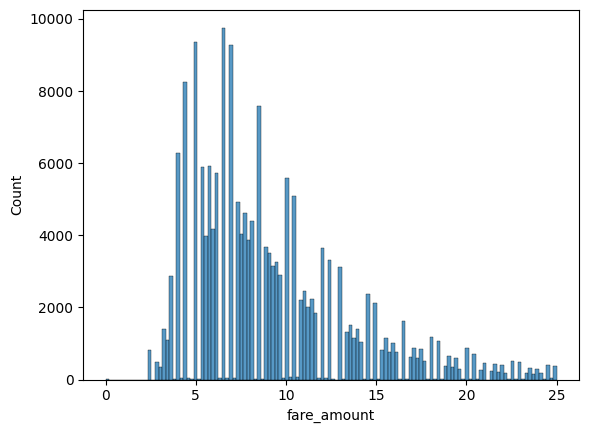

In [ ]:
sns.histplot(df['fare_amount'])

<Axes: ylabel='fare_amount'>

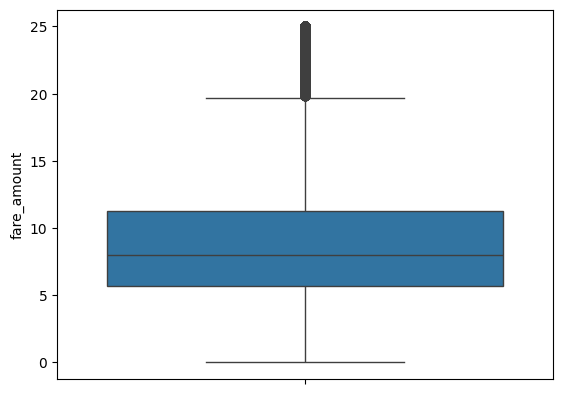

In [ ]:
sns.boxplot(df['fare_amount'])

In [ ]:
df['passenger_count'].median()

np.float64(1.0)

In [ ]:
df=df[(df['passenger_count']>=1) & (df['passenger_count']<=6)]

In [ ]:
df = df[(df['pickup_longitude'] >= -74.25) & (df['pickup_longitude'] <= -73.7)]
df = df[(df['pickup_latitude'] >= 40.5) & (df['pickup_latitude'] <= 40.9)]
df = df[(df['dropoff_longitude'] >= -74.25) & (df['dropoff_longitude'] <= -73.7)]
df = df[(df['dropoff_latitude'] >= 40.5) & (df['dropoff_latitude'] <= 40.9)]


In [ ]:
df.shape

(181201, 9)

In [ ]:
def haversine(lat1,lon1,lat2,lon2):
    dlat=lat2-lat1
    dlon=lon2-lon1
    a=(np.sin(dlat/2)**2)+(np.cos(lat1)*np.cos(lat2)*(np.sin(dlon/2)**2))
    c=2*np.arcsin(np.sqrt(a))
    r=6371
    return c*r

In [ ]:
df['distance_km']=haversine(
    df['pickup_latitude'],df['pickup_longitude'],
    df['dropoff_latitude'],df['dropoff_longitude']
)

In [ ]:
df['pickup_datetime']=pd.to_datetime(df['pickup_datetime'])
df['hour']=df['pickup_datetime'].dt.hour
df['day_of_week']=df['pickup_datetime'].dt.dayofweek
df['month']=df['pickup_datetime'].dt.month
df['year']=df['pickup_datetime'].dt.year

In [ ]:
df=df[(df['distance_km']>0)]

In [ ]:
df.shape

(179400, 14)

In [ ]:
df.drop('key',axis=1,inplace=True)

In [ ]:
features=['fare_amount','passenger_count','hour','month','day_of_week','year','distance_km']

In [ ]:
corr_matrix=df[features].corr()

<Axes: >

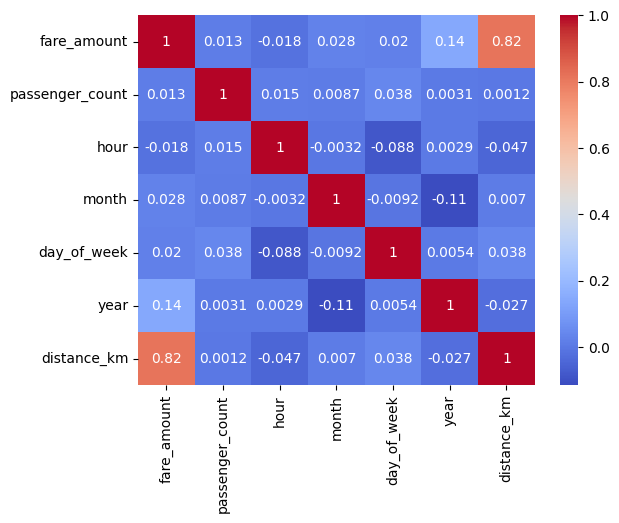

In [ ]:
sns.heatmap(corr_matrix,cmap='coolwarm',annot=True)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,r2_score

In [ ]:
x=df[features]

In [ ]:
x.drop(['fare_amount','hour'],axis=1,inplace=True)

C:\Users\dyuti\AppData\Local\Temp\ipykernel_21020\1985123099.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x.drop(['fare_amount','hour'],axis=1,inplace=True)


In [ ]:
x.columns

Index(['passenger_count', 'month', 'day_of_week', 'year', 'distance_km'], dtype='object')

In [ ]:
y=df['fare_amount']

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
lr=LinearRegression()
lr.fit(x_train,y_train)
pred=lr.predict(x_test)

In [ ]:
r2score=r2_score(y_test,pred)
print(f"R2 score for linear regression is {r2score}")
rmse=np.sqrt(mean_squared_error(y_test,pred))
print(f"RMSE for linear model is {rmse}")

R2 score for linear regression is 0.7043205960947134
RMSE for linear model is 2.4581094219100903


In [ ]:
rf=RandomForestRegressor(n_estimators=50,n_jobs=-1,random_state=42,max_depth=10)
rf.fit(x_train,y_train)
pred=rf.predict(x_test)

In [ ]:
r2score1=r2_score(y_test,pred)
print(f"R2 score for random forest regressor is {r2score1}")
rmse1=np.sqrt(mean_squared_error(y_test,pred))
print(f"RMSE for random forest regressor is {rmse1}")

R2 score for random forest regressor is 0.7524179736908098
RMSE for random forest regressor is 2.249314749031552


Initial shape: (200000, 9)
Columns: ['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_c

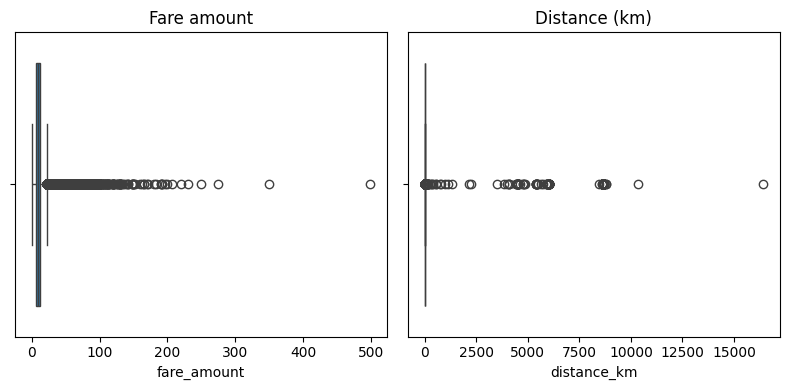

Rows before outlier removal: 199268
Rows after outlier removal: 178721


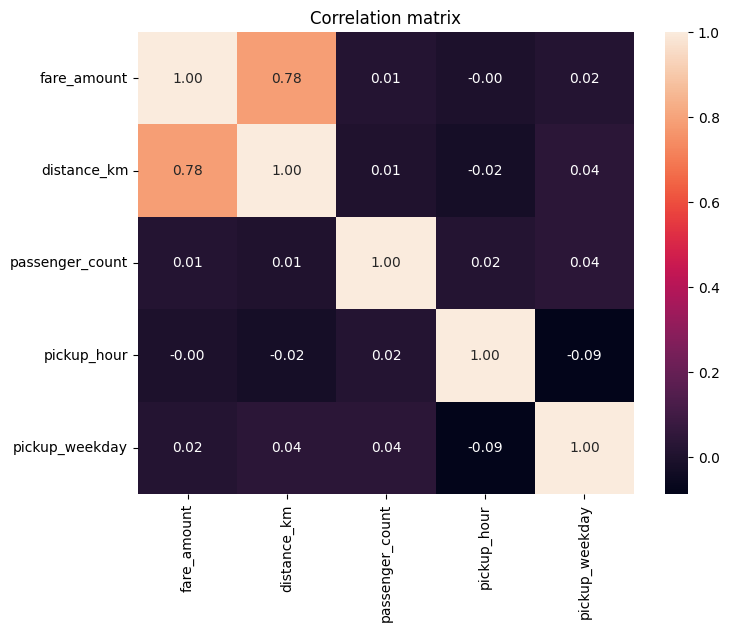


Correlation with fare_amount:
fare_amount        1.000000
distance_km        0.783753
pickup_weekday     0.017218
passenger_count    0.014879
pickup_hour       -0.003085
Name: fare_amount, dtype: float64
Train shape: (142976, 4) Test shape: (35745, 4)

Linear Regression performance:
R2: 0.6074
RMSE: 2.4653
MAE: 1.7629


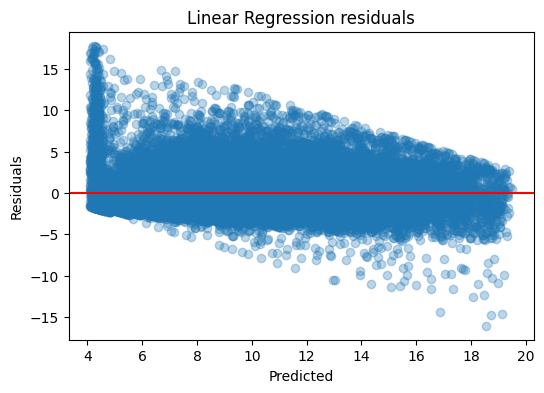

In [ ]:
"""
Complete solution for: Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.

This script covers:
1. Data loading (assumes you have downloaded the CSV from Kaggle and saved as 'uber.csv')
2. Pre-processing and cleaning
3. Feature engineering (Haversine distance, datetime features)
4. Outlier detection and removal (IQR method)
5. Correlation analysis
6. Implementing Linear Regression and Random Forest Regressor
7. Model evaluation and comparison (R2, RMSE, MAE)
8. Improvements: scaling, hyperparameter tuning for Random Forest, feature selection
9. Save trained model

Notes:
- Download dataset from: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset and place it as './uber.csv' or update PATH.
- This is an end-to-end, well-commented script intended for practical exam demonstration.

"""

# --- Imports -----------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib
import warnings
warnings.filterwarnings('ignore')

# --- Utility functions -------------------------------------------------------

def haversine_distance(lat1, lon1, lat2, lon2):
    """Calculate the great circle distance (in kilometers) between two points
    on the earth (specified in decimal degrees).
    Vectorized for pandas series inputs.
    """
    # convert decimal degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    R = 6371  # Radius of earth in kilometers
    return R * c

# --- 1. Load data ------------------------------------------------------------
PATH = './uber.csv'  # change to your path where dataset is downloaded
try:
    df = pd.read_csv(PATH)
except Exception as e:
    raise FileNotFoundError(f"Could not read dataset at {PATH}. Download from Kaggle and place it there. Original error: {e}")

print('Initial shape:', df.shape)
print('Columns:', df.columns.tolist())

# Typical columns: ['key','fare_amount','pickup_datetime','pickup_longitude','pickup_latitude',
# 'dropoff_longitude','dropoff_latitude','passenger_count']

# --- 2. Quick inspect and cleaning ------------------------------------------
print(df.head())
print(df.info())
print('Missing values per column:\n', df.isna().sum())

# Drop rows with missing values in crucial columns
df.dropna(subset=['fare_amount','pickup_datetime','pickup_longitude','pickup_latitude',
                  'dropoff_longitude','dropoff_latitude','passenger_count'], inplace=True)

# Some datasets have invalid fares (negative or zero) and invalid passenger counts
df = df[df['fare_amount'] > 0]
# coerce passenger_count to int and filter reasonable range
df['passenger_count'] = df['passenger_count'].astype(int)
df = df[(df['passenger_count'] >= 1) & (df['passenger_count'] <= 6)]

# Parse pickup_datetime to datetime type
# Some entries include timezone text; pandas can usually parse, but we'll handle safely
try:
    df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], utc=True)
except Exception:
    # try without UTC
    df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')
    df.dropna(subset=['pickup_datetime'], inplace=True)

# --- 3. Feature engineering --------------------------------------------------
# Haversine distance
df['distance_km'] = haversine_distance(df['pickup_latitude'], df['pickup_longitude'],
                                       df['dropoff_latitude'], df['dropoff_longitude'])

# Date-time features
df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_weekday'] = df['pickup_datetime'].dt.weekday

# Sometimes trips with zero distance yet non-zero fare exist -> mark them
print('Zero-distance trips count:', (df['distance_km'] == 0).sum())

# --- 4. Identify outliers ---------------------------------------------------
# We'll inspect fare_amount and distance_km distributions and remove extreme outliers
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
sns.boxplot(x=df['fare_amount'])
plt.title('Fare amount')
plt.subplot(1,2,2)
sns.boxplot(x=df['distance_km'])
plt.title('Distance (km)')
plt.tight_layout()
plt.show()

# Use IQR rule to remove extreme outliers for fare and distance
def iqr_filter(series, lower_q=0.01, upper_q=0.99):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (series >= lower) & (series <= upper)

mask_fare = iqr_filter(df['fare_amount'])
mask_dist = iqr_filter(df['distance_km'])
mask = mask_fare & mask_dist
print('Rows before outlier removal:', len(df))
df = df[mask]
print('Rows after outlier removal:', len(df))

# Further remove unrealistic distances (> 200 km) for urban rides
df = df[df['distance_km'] <= 200]

# --- 5. Correlation check ---------------------------------------------------
plt.figure(figsize=(8,6))
corr = df[['fare_amount','distance_km','passenger_count','pickup_hour','pickup_weekday']].corr()
sns.heatmap(corr, annot=True, fmt='.2f')
plt.title('Correlation matrix')
plt.show()

print('\nCorrelation with fare_amount:')
print(corr['fare_amount'].sort_values(ascending=False))

# --- 6. Prepare data for modeling ------------------------------------------
# We'll use: distance_km, passenger_count, pickup_hour, pickup_weekday
FEATURES = ['distance_km','passenger_count','pickup_hour','pickup_weekday']
TARGET = 'fare_amount'

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)

# Scaling (important for Linear Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 7. Linear Regression ---------------------------------------------------
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

lr_r2 = r2_score(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_mae = mean_absolute_error(y_test, y_pred_lr)

print('\nLinear Regression performance:')
print('R2:', round(lr_r2,4))
print('RMSE:', round(lr_rmse,4))
print('MAE:', round(lr_mae,4))

# Residual plot
plt.figure(figsize=(6,4))
plt.scatter(y_pred_lr, y_test - y_pred_lr, alpha=0.3)
plt.axhline(0, color='r')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Linear Regression residuals')
plt.show()

# --- 8. Random Forest Regressor ---------------------------------------------
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)  # RF handles unscaled data fine

y_pred_rf = rf.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)

print('\nRandom Forest performance (baseline):')
print('R2:', round(rf_r2,4))
print('RMSE:', round(rf_rmse,4))
print('MAE:', round(rf_mae,4))

# Feature importances
fi = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
print('\nFeature importances (RF):')
print(fi)

sns.barplot(x=fi.values, y=fi.index)
plt.title('Feature importances')
plt.show()

# --- 9. Improvements: Hyperparameter tuning for Random Forest ---------------
param_dist = {
    'n_estimators': [100, 200, 400],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rs = RandomizedSearchCV(RandomForestRegressor(random_state=42), param_dist,
                        n_iter=10, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42)
rs.fit(X_train, y_train)
print('\nBest RF params:', rs.best_params_)

best_rf = rs.best_estimator_

y_pred_best_rf = best_rf.predict(X_test)
best_rf_r2 = r2_score(y_test, y_pred_best_rf)
best_rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_best_rf))
best_rf_mae = mean_absolute_error(y_test, y_pred_best_rf)

print('\nRandom Forest after tuning:')
print('R2:', round(best_rf_r2,4))
print('RMSE:', round(best_rf_rmse,4))
print('MAE:', round(best_rf_mae,4))

# --- 10. Compare models -----------------------------------------------------
results = pd.DataFrame({
    'model': ['LinearRegression','RF_baseline','RF_tuned'],
    'R2': [lr_r2, rf_r2, best_rf_r2],
    'RMSE': [lr_rmse, rf_rmse, best_rf_rmse],
    'MAE': [lr_mae, rf_mae, best_rf_mae]
})
print('\nModel comparison:')
print(results)

# Scatter actual vs predicted for best model
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_best_rf, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual fare')
plt.ylabel('Predicted fare')
plt.title('Actual vs Predicted (Best RF)')
plt.show()

# Residual distribution
residuals = y_test - y_pred_best_rf
plt.figure(figsize=(6,4))
sns.histplot(residuals, bins=50, kde=True)
plt.title('Residuals distribution (Best RF)')
plt.show()

# --- 11. Save the best model and the scaler ---------------------------------
joblib.dump(best_rf, 'uber_fare_rf_model.joblib')
joblib.dump(scaler, 'uber_fare_scaler.joblib')
print('\nSaved best model to uber_fare_rf_model.joblib and scaler to uber_fare_scaler.joblib')

# --- 12. Notes on "accuracy score and confusion matrix" ---------------------
# For regression tasks, accuracy score and confusion matrix (which are classification
# metrics) are not applicable. Instead we report R2, RMSE, MAE. If the examiner expects
# a confusion-matrix-like analysis, you can discretize fares into bins (e.g., cheap/medium/expensive)
# and treat it as classification — code snippet below shows how to do that if needed.

# Example: discretize into 3 classes and show confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

bins = [0, 10, 30, np.inf]
labels = [0,1,2]  # 0: cheap, 1: medium, 2: expensive

y_test_binned = pd.cut(y_test, bins=bins, labels=labels).astype(int)
y_pred_binned = pd.cut(y_pred_best_rf, bins=bins, labels=labels).astype(int)

acc = accuracy_score(y_test_binned, y_pred_binned)
cm = confusion_matrix(y_test_binned, y_pred_binned)
print('\nIf you convert to 3 classes (cheap/medium/expensive):')
print('Accuracy:', round(acc,4))
print('Confusion matrix:\n', cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['cheap','medium','expensive'])
disp.plot(cmap='Blues')
plt.show()

# --- End --------------------------------------------------------------------
print('\nAll done. Review code comments for explanations and adjust FEATURES or PATH as needed.')


In [6]:
pip install numpy pandas matplotlib seaborn scikit-learn joblib

  Using cached matplotlib-3.10.7-cp311-cp311-win_amd64.whl (8.1 MB)
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\Users\\r\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\backends\\qt_compat.py'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip available: 22.3 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip available: 22.3 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached matplotlib-3.10.7-cp311-cp311-win_amd64.whl (8.1 MB)
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Using cached scikit_learn-1.7.2-cp311-cp311-win_amd64.whl (8.9 MB)
  Using cached joblib-1.5.2-py3-none-any.whl (308 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached fonttools-4.60.1-cp311-cp311-win_amd64.whl (2.3 MB)
  Using cached kiwisolver-1.4.9-cp311-cp311-win_amd64.whl (73 kB)
  Using cached pillow-12.0.0-cp311-cp311-win_amd64.whl (7.0 MB)
  Using cached pyparsing-3.2.5-py3-none-any.whl (113 kB)
